# Pipeline de Análise Tática de Futebol por Visão Computacional
**Projeto:** `btlearn_soccer_vision`  
**Autor:** Marcos Paulo Pinto Chaves  

Este notebook demonstra de forma interativa e passo a passo as **5 etapas** do pipeline tático:
1. **Detecção Multiclasse** (YOLOv8s treinado + `BallDetector` com pós-processamento temporal);
2. **Rastreamento Temporal** (ByteTrack para jogadores, goleiros e árbitros);
3. **Classificação de Equipes** (Torso crops, KMeans k=2, voto temporal por `track_id` e goleiro espacial);
4. **Homografia Planar** (32 keypoints regulamentares, `cv2.findHomography` com RANSAC e suavização EMA);
5. **Minimapa 2D e Métricas Físicas/Táticas** (velocidade em km/h com filtro >40 km/h, distância acumulada e posse de bola).


## 0. Configurações e Inicialização do Ambiente
Carregamos as configurações centrais do arquivo `configs/default.yaml` e definimos sementes para reprodutibilidade.

In [1]:
import os
import sys
from pathlib import Path

# Garante que a raiz do projeto esteja no sys.path e seja o diretório de trabalho atual
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import cv2
import numpy as np
import matplotlib.pyplot as plt

from src.utils import load_config, resolve, iter_frames
from src.tracking.tracker import PlayerTracker, draw_ball
from src.detection.ball import BallDetector, select_ball
from src.teams.classifier import TeamClassifier, TeamVotingManager
from src.homography.pitch import PitchModel
from src.homography.estimator import HomographyEstimator, project_point
from src.homography.metrics import draw_pitch_wireframe
from src.metrics.speed_distance import PhysicalMetricsTracker
from src.metrics.possession import BallPossessionTracker
from src.metrics.minimap import MinimapRenderer

cfg = load_config('configs/default.yaml')
video_path = resolve('data/121364_0.mp4')
weights_path = resolve('runs/detector/weights/best.pt')

print(f'Raiz do projeto configurada: {project_root}')
print(f'Configurações carregadas com sucesso! Classes: {cfg["detection"]["classes"]}')


Raiz do projeto configurada: d:\btlearn_soccer_vision
Configurações carregadas com sucesso! Classes: ['ball', 'goalkeeper', 'player', 'referee']


## 1. Etapa 1: Detecção Multiclasse e Tratamento Especial da Bola
Carregamos o modelo treinado YOLOv8s e o `BallDetector` que aplica limiar baixo (`conf=0.10`) com filtro de salto plausível.

In [2]:
# Carrega o primeiro frame do vídeo de teste
for idx, frame in iter_frames(video_path):
    sample_frame = frame.copy()
    break

ball_det = BallDetector(
    weights=str(weights_path),
    ball_class_id=cfg['detection']['classes'].index('ball'),
    conf=cfg['ball']['conf'],
    imgsz=cfg['detection']['infer']['imgsz'],
    slicing=False,
)

cands = ball_det.candidates(sample_frame)
print(f"Candidatos a bola encontrados: {len(cands)}")
best_ball = select_ball(cands, None, cfg['ball']['max_jump_px'])
if best_ball is not None:
    print(f"Bola selecionada nas coordenadas da imagem: ({best_ball[0]:.1f}, {best_ball[1]:.1f})")


Candidatos a bola encontrados: 3
Bola selecionada nas coordenadas da imagem: (1350.4, 357.1)


## 2. Etapa 2: Rastreamento Temporal com ByteTrack
Instanciamos o rastreador `PlayerTracker` para manter identidades estáveis de jogadores, goleiros e árbitros.

In [3]:
tracker = PlayerTracker(
    weights=weights_path,
    all_classes=cfg['detection']['classes'],
    track_classes=cfg['tracking']['track_classes'],
    conf=cfg['tracking']['conf'],
    imgsz=cfg['tracking']['imgsz'],
)

tracked_players = tracker.track_frame(sample_frame, persist=True)
print(f"Jogadores rastreados no frame: {len(tracked_players)}")
for p in tracked_players[:5]:
    print(f"ID #{p.track_id:02d} ({p.cls_name}): bbox={tuple(round(v, 1) for v in p.bbox)}, pe={tuple(round(v, 1) for v in p.bottom_center)}")


Jogadores rastreados no frame: 23
ID #01 (player): bbox=(1642.8, 542.8, 1679.0, 593.1), pe=(1660.9, 593.1)
ID #02 (player): bbox=(1368.9, 469.3, 1404.7, 520.2), pe=(1386.8, 520.2)
ID #03 (goalkeeper): bbox=(184.6, 415.0, 205.7, 461.3), pe=(195.1, 461.3)
ID #04 (player): bbox=(237.5, 500.0, 263.2, 548.3), pe=(250.4, 548.3)
ID #05 (player): bbox=(404.2, 531.8, 429.5, 582.5), pe=(416.8, 582.5)


## 3. Etapa 3: Classificação de Times e Regras Táticas
Extraímos a região do tronco dos jogadores (15% a 55% da altura) e aplicamos o modelo de clusterização KMeans ($k=2$) com votação por maioria temporal.

In [4]:
clf = TeamClassifier(
    method=cfg['teams'].get('method', 'hsv'),
    dim_reduction=cfg['teams'].get('dim_reduction', 'none'),
    k=2,
)

# Coleta amostras de torso em 20 frames para ajuste do K-Means
sample_crops = []
for idx, frame in iter_frames(video_path):
    if idx >= 20:
        break
    players = tracker.track_frame(frame, persist=False)
    for p in players:
        if p.cls_name == 'player':
            crop = p.torso_crop(frame)
            if crop.size > 0 and crop.shape[0] >= 10 and crop.shape[1] >= 10:
                sample_crops.append(crop)

clf.fit(sample_crops)
print(f"Classificador ajustado com {len(sample_crops)} recortes de torso!")
print(f"Cores medias RGB aprendidas: Time 0={clf.team_colors[0][::-1]}, Time 1={clf.team_colors[1][::-1]}")


d:\btlearn_soccer_vision\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-24 01:10:49,468 | INFO | src.teams.features | Carregando modelo SigLIP (google/siglip-base-patch16-224) em cuda...
2026-10-24 01:10:49,774 | INFO | httpx2 | HTTP Request: GET https://huggingface.co/api/models/google/siglip-base-patch16-224 "HTTP/1.1 200 OK"
2026-10-24 01:10:49,980 | INFO | httpx2 | HTTP Request: GET https://huggingface.co/api/models/google/siglip-base-patch16-224/revision/main "HTTP/1.1 200 OK"
Loading weights: 100%|██████████| 208/208 [00:00<00:00, 493.03it/s]
[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-224
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.en

Classificador ajustado com 400 recortes de torso!
Cores medias RGB aprendidas: Time 0=(140, 180, 99), Time 1=(152, 125, 86)


## 4. Etapa 4: Calibração de Câmera e Homografia Planar
Utilizamos o modelo de pose de 32 marcos na resolução nativa `imgsz=640` e o estimador com RANSAC e suavização temporal EMA.

In [6]:
pitch = PitchModel(length=105.0, width=68.0)
estimator = HomographyEstimator(
    pitch_model=pitch,
    conf_threshold=0.35,
    ransac_threshold=6.0,
    smooth_alpha=0.15,
    imgsz=640,
)

res = estimator.estimate(sample_frame, use_smoothing=True)
print(f"Homografia estimada com sucesso? {res.H is not None}")
print(f"Keypoints detectados: {res.num_keypoints}, Inliers RANSAC: {res.inliers_count}")

# Projeta um jogador para coordenadas métricas
if res.H is not None and tracked_players:
    p0 = tracked_players[0]
    m_pos = project_point(p0.bottom_center, res.H)
    print(f"Jogador #{p0.track_id} no chao ({p0.bottom_center[0]:.1f}px, {p0.bottom_center[1]:.1f}px) -> Campo ({m_pos[0]:.2f}m, {m_pos[1]:.2f}m)")


2026-10-24 01:11:07,249 | INFO | httpx2 | HTTP Request: HEAD https://huggingface.co/martinjolif/yolo-football-pitch-detection/resolve/main/yolo-football-pitch-detection.pt "HTTP/1.1 302 Found"


Homografia estimada com sucesso? True
Keypoints detectados: 16, Inliers RANSAC: 16
Jogador #1 no chao (1660.9px, 593.1px) -> Campo (64.89m, 40.12m)


## 5. Etapa 5: Minimapa 2D, Métricas Físicas e Posse de Bola
Integramos o cálculo de velocidade instantânea ($v \le 40$ km/h), distância acumulada e renderização do radar 2D estilo transmissão esportiva.

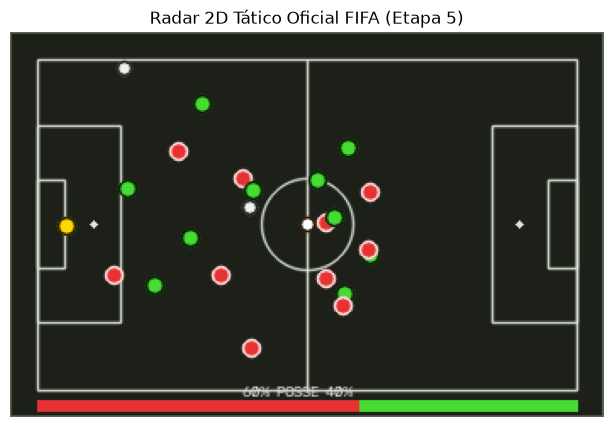

In [7]:
phys_tracker = PhysicalMetricsTracker(fps=25.0, max_speed_kmh=40.0)
poss_tracker = BallPossessionTracker(possession_radius_m=2.0)
minimap_renderer = MinimapRenderer(pitch_model=pitch, width=350, height=227)

# Prepara informações dos jogadores para o radar
voting_mgr = TeamVotingManager(history_window=50)
player_info_list = []
for p in tracked_players:
    tid = voting_mgr.assign_team(p, 0 if p.track_id % 2 == 0 else 1, [])
    pos_m = project_point(p.bottom_center, res.H) if res.H is not None else (float('nan'), float('nan'))
    speed, dist = phys_tracker.update(p.track_id, pos_m, frame_idx=0)
    player_info_list.append({
        'track_id': p.track_id,
        'team_id': tid,
        'pos_m': pos_m,
        'cls_name': p.cls_name,
        'is_referee': (p.cls_name == 'referee'),
        'is_goalkeeper': (p.cls_name == 'goalkeeper'),
    })

radar_img = minimap_renderer.render(
    players=player_info_list,
    ball_pos_m=(52.5, 34.0),
    possession_info={'team_0_pct': 60.0, 'team_1_pct': 40.0},
)

# Plota o minimapa 2D gerado
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(radar_img, cv2.COLOR_BGR2RGB))
plt.title('Radar 2D Tático Oficial FIFA (Etapa 5)')
plt.axis('off')
plt.show()


## 6. Execução do Pipeline Completo Integrado
Para gerar o vídeo tático final com todas as anotações visuais, wireframe, métricas de jogadores e minimapa, execute:

```bash
python -m scripts.run_pipeline --video data/121364_0.mp4 --max-frames 150 --output runs/full_tactical_analysis.mp4
```

Os resultados e métricas finais consolidados ficam gravados em `runs/tactical_metrics.json`.